# Setup

This project requires Python 3.7 or above:

In [7]:
import sys

assert sys.version_info >= (3, 7)

It also requires Scikit-Learn ≥ 1.0.1:

In [8]:
from packaging import version
import sklearn

assert version.parse(sklearn.__version__) >= version.parse("1.0.1")

As we did in previous chapters, let's define the default font sizes to make the figures prettier:

In [18]:
import matplotlib.pyplot as plt

plt.rc('font', size=14) #Setting the font size for everything to 14
plt.rc('axes', labelsize=13, titlesize=15) #changing the font size for the x-axis and y-axis labels to 13, and the font size of x-axis and y-axis title to 15
plt.rc('legend', fontsize=12) #changing the font size for the legend to 12
plt.rc('xtick', labelsize=10) #chainging the font size of the number that represent the x-axis to 10
plt.rc('ytick', labelsize=10) #chainging the font size of the number that represent the y-axis to 10

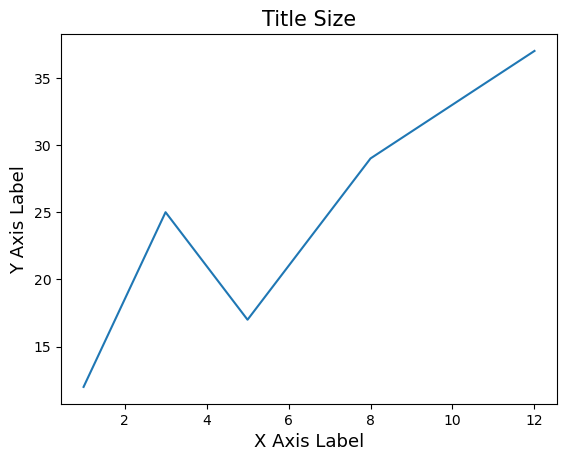

In [19]:
import matplotlib.pyplot as plt

# Sample data
x = [1, 3, 5, 8, 12]
y = [12, 25, 17, 29, 37]

plt.plot(x, y)

# Adding title and axis labels
plt.title("Title Size")
plt.xlabel("X Axis Label")
plt.ylabel("Y Axis Label")

# Show the plot
plt.show()

And let's create the `images/unsupervised_learning` folder (if it doesn't already exist), and define the `save_fig()` function which is used through this notebook to save the figures in high-res for the book:

In [4]:
import numpy as np

First, let's import a few common modules, ensure MatplotLib plots figures inline and prepare a function to save the figures.

# Clustering

## K-Means

**Fit and predict**

Let's train a K-Means clusterer on a dataset if blobs. It will try to find each blob's center and assign each instance to the closest blob:

In [5]:
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

# extra code – the exact arguments of make_blobs() are not important
blob_centers = np.array([[ 0.2,  2.3], [-1.5 ,  2.3], [-2.8,  1.8],
                         [-2.8,  2.8], [-2.8,  1.3]])
blob_std = np.array([0.4, 0.3, 0.1, 0.1, 0.1])
X, y = make_blobs(n_samples=2000, centers=blob_centers, cluster_std=blob_std,
                  random_state=7) #assigning 2 variable because the output of the function make_blobs() produces 2 outputs that are needed to be assigned to 2 varibales; However since KMeans is an unsupervised learning method, y is not needed, and the output data that we need is only stored in X (the first variable)

k = 5
kmeans = KMeans(n_clusters=k, random_state=42)
y_pred = kmeans.fit_predict(X)

## let's read the data

In [83]:
import pandas as pd
df = pd.read_csv('datasets/housing/housepriceAs1.csv')

## Let's index the data 

Now let's plot them:

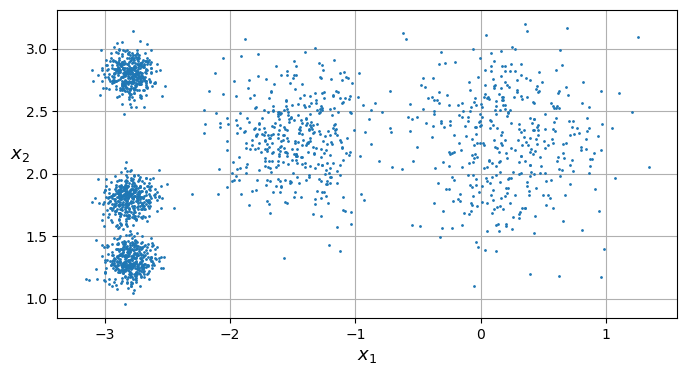

In [ ]:
# extra code – this cell generates and saves Figure 9–2

def plot_clusters(X, y=None): #previously we said "#assigning 2 variable because the output of the function make_blobs() produces 2 outputs that are needed to be assigned to 2 varibales"; However, since y is not used when dealing with KMeans because it is an unsupervised clustering method, we assign the y=None.
    plt.scatter(X[:, 0], X[:, 1], c=y, s=1)
    plt.xlabel("$x_1$")
    plt.ylabel("$x_2$", rotation=0)

plt.figure(figsize=(8, 4))
plot_clusters(X)
plt.gca().set_axisbelow(True)
plt.grid()
plt.show()

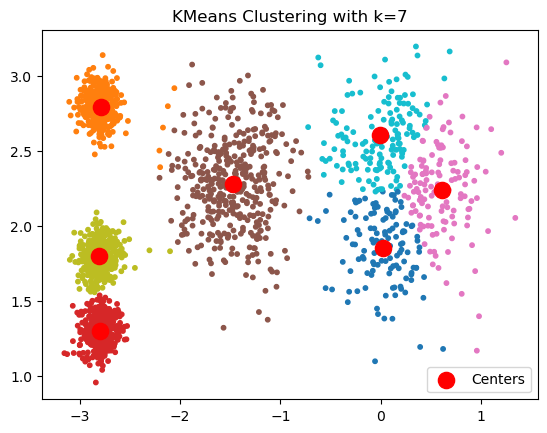

In [6]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

k = 7
kmeans = KMeans(n_clusters=k, random_state=42) #creating an instance of the KMeans class and assigning it to the variable kmeans
#n_clusters represents the amount of the clusters the algorithm should look for
#setting random_state for having a reproducible output
y_pred = kmeans.fit_predict(X) #the function fit_predict() here learns from the data in variable X, and that's what we call FIT. Also, the function fit_predict() here makes calculated guess for each sample(data point) trying to say which cluster_center does this data point(sample) belong to, and that's what we call PREDICT

plt.scatter(X[:, 0], X[:, 1], c=y_pred, cmap='tab10', s=10) #selecting all the rows in the first two columns, and (c stands for color) then gives different colors for the data points(samples) depending on which cluster_center they belong to, and (cmp stands for color map) also allowing 10 or less different colors to be enabled for usage, and lastly (s stands for size) setting the size to 10
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
            c='red', marker='o', s=136, label='Centers') #drawing a square on each centriod(the center of each cluster). In marker, (o stands for circle), also (s stands for square, but not used in this case). Also the size of the circle is 136, and In the label, this label belongs to the title of the legend. Finally, (c stands for) the color of the circle will be red.
plt.legend()
plt.title(f'KMeans Clustering with k={k}')
plt.show()


Each instance was assigned to one of the 5 clusters:

In [ ]:
len(y_pred) #checking the length of the array stored in "y_pred" 

2000

In [ ]:
y_pred #y_pred stores a calculated guess for each data point from the samples to guess which centeriod each data point would belong to (note: samples have been manually adjusted before in n_samples using the function make_blobs(), and can be accessed for view only using len(y_pred))

array([2, 5, 4, ..., 1, 6, 5], dtype=int32)

And the following 5 _centroids_ (i.e., cluster centers) were estimated:

In [ ]:
kmeans.cluster_centers_ #displaying the position of (in the form of x-axis and y-axis coordinations) of the cluster_center, which is also called centriod.

array([[ 0.20876306,  2.25551336],
       [-2.79290307,  2.79641063],
       [-2.80214068,  1.55162671],
       [-1.46679593,  2.28585348]])

Note that the `KMeans` instance preserves the labels of the instances it was trained on. Somewhat confusingly, in this context, the _label_ of an instance is the index of the cluster that instance gets assigned to (they are not targets, they are predictions):

In [ ]:
kmeans.labels_ #these are the predictions, not targets.

array([2, 5, 4, ..., 1, 6, 5], dtype=int32)

In [7]:
len(kmeans.labels_)

2000

Of course, we can predict the labels of new instances:

In [38]:
import numpy as np

X_new = np.array([[0, 2], [3, 2], [-3, 3], [-3, 2.5]])
kmeans.predict(X_new)

array([0, 4, 1, 1], dtype=int32)

**Hard Clustering _vs_ Soft Clustering**

Rather than arbitrarily choosing the closest cluster for each instance, which is called _hard clustering_, it might be better to measure the distance of each instance to all 5 centroids. This is what the `transform()` method does:

In [39]:
kmeans.transform(X_new).round(2)

array([[0.12, 2.9 , 2.84, 1.5 , 0.63],
       [3.07, 5.85, 5.82, 4.48, 2.56],
       [3.07, 0.29, 1.46, 1.69, 3.52],
       [2.96, 0.36, 0.97, 1.54, 3.47]])

### Inertia

To select the best model, we will need a way to evaluate a K-Mean model's performance. Unfortunately, clustering is an unsupervised task, so we do not have the targets. But at least we can measure the distance between each instance and its centroid. This is the idea behind the _inertia_ metric:

In [40]:
kmeans.inertia_

224.07433122515732

### Multiple Initializations

So one approach to solve the variability issue is to simply run the K-Means algorithm multiple times with different random initializations, and select the solution that minimizes the inertia.

When you set the `n_init` hyperparameter, Scikit-Learn runs the original algorithm `n_init` times, and selects the solution that minimizes the inertia. By default, Scikit-Learn sets `n_init=10`.

In [8]:
# extra code
kmeans_rnd_10_inits = KMeans(n_clusters=5, init="random", n_init=10,
                             random_state=2)
kmeans_rnd_10_inits.fit(X)

,n_clusters,5
,init,'random'
,n_init,10
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,2
,copy_x,True
,algorithm,'lloyd'


As you can see, we end up with the initial model, which is certainly the optimal K-Means solution (at least in terms of inertia, and assuming $k=5$).

In [10]:
kmeans_rnd_10_inits.inertia_

211.5985372581684

### Finding the optimal number of clusters

No, we cannot simply take the value of $k$ that minimizes the inertia, since it keeps getting lower as we increase $k$. Indeed, the more clusters there are, the closer each instance will be to its closest centroid, and therefore the lower the inertia will be. However, we can plot the inertia as a function of $k$ and analyze the resulting curve:

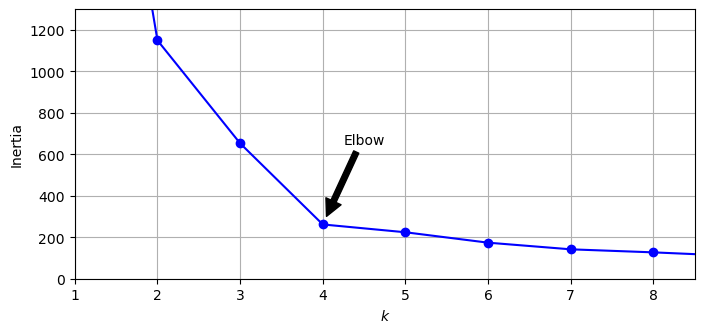

In [ ]:
# extra code – this cell generates and saves Figure 9–8

kmeans_per_k = [KMeans(n_clusters=k, random_state=42).fit(X) #here fit() means that we are creating a model/instance of the class KMeans that will be already fitted(meaning has learned from the data in variable X) since we are using the fit() while creating the instance of the class 
                for k in range(1, 10)] #So we can not select a range starting 0 only logically it would not make sense to create a KMean model with 0 clusters, so we are starting with one range(1,10), and since range() excludes the last 10; This code is creating 9 models, one for each case. The case of when there are 1,2,3,4,5,6,7,8,9 clusters. so the for loop is assuming when k=1, and then k=2, and so on until k=9, and creates an instance of the class KMeans for each case.
inertias = [model.inertia_ for model in kmeans_per_k]

plt.figure(figsize=(8, 3.5))
plt.plot(range(1, 10), inertias, "bo-")
plt.xlabel("$k$")
plt.ylabel("Inertia")
plt.annotate("", xy=(4, inertias[3]), xytext=(4.45, 650),
             arrowprops=dict(facecolor='black', shrink=0.1))
plt.text(4.5, 650, "Elbow", horizontalalignment="center")
plt.axis([1, 8.5, 0, 1300])
plt.grid()
plt.show()

As you can see, there is an elbow at $k=4$, which means that less clusters than that would be bad, and more clusters would not help much and might cut clusters in half. So $k=4$ is a pretty good choice. Of course in this example it is not perfect since it means that the two blobs in the lower left will be considered as just a single cluster, but it's a pretty good clustering nonetheless.

Another approach is to look at the _silhouette score_, which is the mean _silhouette coefficient_ over all the instances. An instance's silhouette coefficient is equal to (_b_ - _a_) / max(_a_, _b_) where _a_ is the mean distance to the other instances in the same cluster (it is the _mean intra-cluster distance_), and _b_ is the _mean nearest-cluster distance_, that is the mean distance to the instances of the next closest cluster (defined as the one that minimizes _b_, excluding the instance's own cluster). The silhouette coefficient can vary between -1 and +1: a coefficient close to +1 means that the instance is well inside its own cluster and far from other clusters, while a coefficient close to 0 means that it is close to a cluster boundary, and finally a coefficient close to -1 means that the instance may have been assigned to the wrong cluster.

Let's plot the silhouette score as a function of $k$:

In [12]:
from sklearn.metrics import silhouette_score

In [13]:
silhouette_score(X, kmeans.labels_)

0.6073764342983767

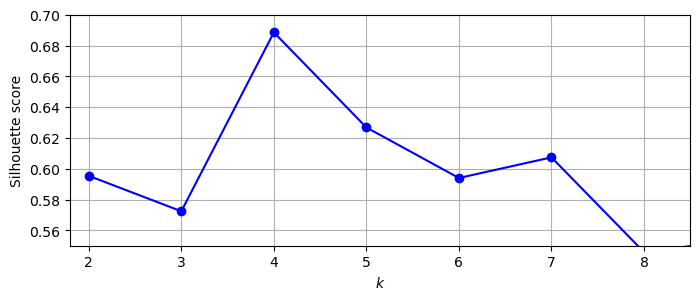

In [ ]:
# extra code – this cell generates and saves Figure 9–9

silhouette_scores = [silhouette_score(X, model.labels_) #the first input in the silhouette_score() function represents the dataset which contains the coordinations for the dataPoints, and the second input in the silhouette_score() function represents the labels which specifies which cluster does each data belong to.
                     for model in kmeans_per_k[1:]]

plt.figure(figsize=(8, 3))
plt.plot(range(2, 10), silhouette_scores, "bo-")
plt.xlabel("$k$")
plt.ylabel("Silhouette score")
plt.axis([1.8, 8.5, 0.55, 0.7])
plt.grid()
plt.show()

As you can see, this visualization is much richer than the previous one: in particular, although it confirms that $k=4$ is a very good choice, but it also underlines the fact that $k=5$ is quite good as well.

In [15]:
kmeans.n_clusters

7

In [16]:
kmeans.labels_

array([2, 5, 4, ..., 1, 6, 5], dtype=int32)

In [17]:
kmeans

,n_clusters,7
,init,'k-means++'
,n_init,'auto'
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


In [24]:
len(kmeans_per_k)

9

In [25]:
len(silhouette_scores)

8

In [30]:
kmeansinstance1 = KMeans(n_clusters=1).fit(X)
print(kmeansinstance1.inertia_)

3534.836087167079


In [32]:
kmeansinstance2 = KMeans(n_clusters=2).fit(X)
print(kmeansinstance2.inertia_)

1149.9071172167878


In [33]:
kmeansinstance3 = KMeans(n_clusters=3).fit(X)
print(kmeansinstance3.inertia_)

653.2167190021553


In [34]:
kmeansinstance4 = KMeans(n_clusters=4).fit(X)
print(kmeansinstance4.inertia_)

261.79677785694696


In [35]:
kmeansinstance5 = KMeans(n_clusters=5).fit(X)
print(kmeansinstance5.inertia_)

236.93978215938483


In [36]:
kmeansinstance6 = KMeans(n_clusters=6).fit(X)
print(kmeansinstance6.inertia_)

188.62739693950016


In [37]:
kmeansinstance7 = KMeans(n_clusters=7).fit(X)
print(kmeansinstance7.inertia_)

169.18150200948654


In [38]:
kmeansinstance8 = KMeans(n_clusters=8).fit(X)
print(kmeansinstance8.inertia_)

119.21447063659323


In [41]:
kmeansinstance9 = KMeans(n_clusters=9).fit(X)
print(kmeansinstance9.inertia_)

107.65928170671955


In [ ]:
kmeansinstance20 = KMeans(n_clusters=20).fit(X)
print(kmeansinstance20.inertia_)

55.597299060261534


In [43]:
kmeansinstance30 = KMeans(n_clusters=30).fit(X)
print(kmeansinstance30.inertia_)

38.34924606374552


In [44]:
kmeansinstance150 = KMeans(n_clusters=150).fit(X)
print(kmeansinstance150.inertia_)

6.653957308635585


## 10. Cluster the Olivetti Faces Dataset

*Exercise: The classic Olivetti faces dataset contains 400 grayscale 64 × 64–pixel images of faces. Each image is flattened to a 1D vector of size 4,096. 40 different people were photographed (10 times each), and the usual task is to train a model that can predict which person is represented in each picture. Load the dataset using the `sklearn.datasets.fetch_olivetti_faces()` function.*

In [8]:
from sklearn.datasets import fetch_olivetti_faces

olivetti = fetch_olivetti_faces() #calling the function fetch_olivetti_faces, and this function returns a dataset and stores it in the variable olivetti

In [ ]:
print(olivetti.DESCR) #printing the description of the dataset stored in the variable olivetti

.. _olivetti_faces_dataset:

The Olivetti faces dataset
--------------------------

`This dataset contains a set of face images`_ taken between April 1992 and
April 1994 at AT&T Laboratories Cambridge. The
:func:`sklearn.datasets.fetch_olivetti_faces` function is the data
fetching / caching function that downloads the data
archive from AT&T.

.. _This dataset contains a set of face images: https://cam-orl.co.uk/facedatabase.html

As described on the original website:

    There are ten different images of each of 40 distinct subjects. For some
    subjects, the images were taken at different times, varying the lighting,
    facial expressions (open / closed eyes, smiling / not smiling) and facial
    details (glasses / no glasses). All the images were taken against a dark
    homogeneous background with the subjects in an upright, frontal position
    (with tolerance for some side movement).

**Data Set Characteristics:**

=================   =====================
Classes              

In [50]:
olivetti.images.shape

(400, 64, 64)

In [51]:
olivetti.data.shape

(400, 4096)

In [52]:
olivetti.target

array([ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  3,  3,  3,  3,
        3,  3,  3,  3,  3,  3,  4,  4,  4,  4,  4,  4,  4,  4,  4,  4,  5,
        5,  5,  5,  5,  5,  5,  5,  5,  5,  6,  6,  6,  6,  6,  6,  6,  6,
        6,  6,  7,  7,  7,  7,  7,  7,  7,  7,  7,  7,  8,  8,  8,  8,  8,
        8,  8,  8,  8,  8,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9, 10, 10,
       10, 10, 10, 10, 10, 10, 10, 10, 11, 11, 11, 11, 11, 11, 11, 11, 11,
       11, 12, 12, 12, 12, 12, 12, 12, 12, 12, 12, 13, 13, 13, 13, 13, 13,
       13, 13, 13, 13, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 15, 15, 15,
       15, 15, 15, 15, 15, 15, 15, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16,
       17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 18, 18, 18, 18, 18, 18, 18,
       18, 18, 18, 19, 19, 19, 19, 19, 19, 19, 19, 19, 19, 20, 20, 20, 20,
       20, 20, 20, 20, 20, 20, 21, 21, 21, 21, 21, 21, 21, 21, 21, 21, 22,
       22, 22, 22, 22, 22

*Exercise: Then split it into a training set, a validation set, and a test set (note that the dataset is already scaled between 0 and 1). Since the dataset is quite small, you probably want to use stratified sampling to ensure that there are the same number of images per person in each set.*

In [9]:
from sklearn.model_selection import StratifiedShuffleSplit

strat_split = StratifiedShuffleSplit(n_splits=1, test_size=40, random_state=42) #using the class StratifiedShuffleSplit, we are setting rules for splitting like number of splits, the test size, and then we store these information in a variable called strat_split
train_valid_idx, test_idx = next(strat_split.split(olivetti.data,
                                                   olivetti.target)) #the output from the split method will be the number of indices(plural of index) for training&validation, which will be stored in the variable train_valid_idx. Also the output from the split method will include the number of indices(plural of index) for testing, which will be stored in the variable test_idx. Be aware that the first output is always the training&validation sample.
X_train_valid = olivetti.data[train_valid_idx] #because we have the incidices stored in train_valid_idx, now we can access the corresponding images and store them in the variable X_train_valid. Here for the variable train_valid_idx, we should have 360 images, since we had an overall 400 images, and we only selected 40 for the test size in the splitting method. (400-40=360)
y_train_valid = olivetti.target[train_valid_idx] #because we have the incidices stored in train_valid_idx, now we can access their data labels(which is the iDs of the 40 persons) and store their iDs in the variable y_train_valid. Here for the variable train_valid_idx, we should have 360 images, since we had an overall 400 images, and we only selected 40 for the test size in the splitting method. (400-40=360)
X_test = olivetti.data[test_idx] #because we have the incidices stored in test_idx, now we can access the corresponding images and store them in the variable X_test. Here for the variable test_idx, we should have 40 images, since we had an overall 400 images, and we only selected 40 for the test size in the splitting method. (400-360=40, or we selected 40)
y_test = olivetti.target[test_idx] #because we have the incidices stored in test_idx, now we can access their data labels(which is the iDs of the 40 persons) and store their iDs in the variable y_test.  Here for the variable test_idx, we should have 40 images, since we had an overall 400 images, and we only selected 40 for the splitting size. (400-360=40, or we selected 40)

strat_split = StratifiedShuffleSplit(n_splits=1, test_size=80, random_state=43) 
train_idx, valid_idx = next(strat_split.split(X_train_valid, y_train_valid)) #the output from the split method will be the number of indices(plural of index) for training, which will be stored in the variable train_idx. Also the output from the split method will include the number of indices(plural of index) for validation, which will be stored in the variable valid_idx. Be aware that the first output is always the training sample.
X_train = X_train_valid[train_idx] #because we have the incidices stored in train_idx, now we can access the corresponding images and store them in the variable X_train. Here for the variable X_train, we should have 280 images, since we had an overall 360 images, and we only selected 80 for the splitting size. (360-80=280)
y_train = y_train_valid[train_idx] #because we have the incidices stored in train_idx, now we can access their data labels(which is the iDs of the 40 persons) and store their iDs in the variable y_train. Here for the variable train_idx, we should have 280 images, since we had an overall 360 images, and we only selected 80 for the splitting size. (360-80=280)
X_valid = X_train_valid[valid_idx] #because we have the incidices stored in valid_idx, now we can access the corresponding images and store them in the variable X_valid. Here for the variable valid_idx, we should have 80 images, since we had an overall 360 images, and we only selected 80 for the splitting size. (360-280=80, or we selected 80)
y_valid = y_train_valid[valid_idx] #because we have the incidices stored in valid_idx, now we can access their data labels(which is the iDs of the 40 persons) and store their iDs in the variable y_valid.  Here for the variable valid_idx, we should have 80 images, since we had an overall 360 images, and we only selected 80 for the splitting size (360-280=80, or we selected 80)

In [ ]:
#(and since each person of the 40 person has taken 10 pictures, so we have 400 images)
# y refers to the assigned iD that connects each to picture to the right person
print(X_train_valid.shape, y_train_valid.shape) #for training&validation (360 images), which is not really used for training nor for validation. It is not used at all, but we needed to created to be able to split, and three different sets, one for testing, other for training, and third for validation.
print(X_test.shape, y_test.shape) #for testing (40 images)
print(X_train.shape, y_train.shape) #for training (280 images)
print(X_valid.shape, y_valid.shape) #for validation (80 images)

(360, 4096) (360,)
(40, 4096) (40,)
(280, 4096) (280,)
(80, 4096) (80,)


In [13]:
X_train

array([[0.70247936, 0.74380165, 0.77272725, ..., 0.21900827, 0.45867768,
        0.6363636 ],
       [0.3553719 , 0.39256197, 0.446281  , ..., 0.17355372, 0.18181819,
        0.18595041],
       [0.3305785 , 0.4090909 , 0.5495868 , ..., 0.6983471 , 0.70247936,
        0.59917355],
       ...,
       [0.28099173, 0.19008264, 0.19008264, ..., 0.30578512, 0.3181818 ,
        0.3181818 ],
       [0.338843  , 0.40495867, 0.5082645 , ..., 0.58264464, 0.57024795,
        0.5495868 ],
       [0.6404959 , 0.6818182 , 0.71900827, ..., 0.4090909 , 0.4214876 ,
        0.41735536]], dtype=float32)

*Exercise: Next, cluster the images using K-Means, and ensure that you have a good number of clusters (using one of the techniques discussed in this chapter).*

In [ ]:
from sklearn.cluster import KMeans

k_range = range(5, 150, 5)
kmeans_per_k = []
for i, k in enumerate(k_range, start=0): #adding the enmerate function to link each model with its corresonding index
    print(f"index{i} equals to k={k}")
    kmeans = KMeans(n_clusters=k, random_state=42) #here we create an instance/model of the class KMeans 
    kmeans.fit(X_train) #we use the function fit() to train the model, and allow the model to learn from the data stored in the varible X_train
    kmeans_per_k.append(kmeans) #here we just add the result to the list stored in variable kmeans_per_k

index0 equals to k=5
index1 equals to k=10
index2 equals to k=15
index3 equals to k=20
index4 equals to k=25
index5 equals to k=30
index6 equals to k=35
index7 equals to k=40
index8 equals to k=45
index9 equals to k=50
index10 equals to k=55
index11 equals to k=60
index12 equals to k=65
index13 equals to k=70
index14 equals to k=75
index15 equals to k=80
index16 equals to k=85
index17 equals to k=90
index18 equals to k=95
index19 equals to k=100
index20 equals to k=105
index21 equals to k=110
index22 equals to k=115
index23 equals to k=120
index24 equals to k=125
index25 equals to k=130
index26 equals to k=135
index27 equals to k=140
index28 equals to k=145


In [25]:
for kk in kmeans_per_k:
    print(f"kk={kk}") #now we see the models that are stored in the list 
for kk in kmeans_per_k:
    print(f"kk={kk}")

kk=KMeans(n_clusters=5, random_state=42)
kk=KMeans(n_clusters=10, random_state=42)
kk=KMeans(n_clusters=15, random_state=42)
kk=KMeans(n_clusters=20, random_state=42)
kk=KMeans(n_clusters=25, random_state=42)
kk=KMeans(n_clusters=30, random_state=42)
kk=KMeans(n_clusters=35, random_state=42)
kk=KMeans(n_clusters=40, random_state=42)
kk=KMeans(n_clusters=45, random_state=42)
kk=KMeans(n_clusters=50, random_state=42)
kk=KMeans(n_clusters=55, random_state=42)
kk=KMeans(n_clusters=60, random_state=42)
kk=KMeans(n_clusters=65, random_state=42)
kk=KMeans(n_clusters=70, random_state=42)
kk=KMeans(n_clusters=75, random_state=42)
kk=KMeans(n_clusters=80, random_state=42)
kk=KMeans(n_clusters=85, random_state=42)
kk=KMeans(n_clusters=90, random_state=42)
kk=KMeans(n_clusters=95, random_state=42)
kk=KMeans(n_clusters=100, random_state=42)
kk=KMeans(n_clusters=105, random_state=42)
kk=KMeans(n_clusters=110, random_state=42)
kk=KMeans(n_clusters=115, random_state=42)
kk=KMeans(n_clusters=120, rando

In [17]:
for kk in kmeans_per_k:
    print(f"kk={kk.labels_}") #Now we can see the data points for each trained model kmeans_per_k, and how each model is different depending on the number of clusters, and the first model has 296 data points, and the second model has 332 data points
for kk in kmeans_per_k:
    print(f"kk={kk.labels_.shape}")

kk=[2 0 3 3 2 1 2 3 2 1 3 3 4 1 2 3 2 4 1 1 1 4 0 1 1 0 4 1 2 2 1 4 0 2 3 3 2
 3 2 4 1 4 3 1 1 3 0 4 1 3 0 2 1 1 1 3 1 0 0 1 1 2 3 4 4 1 1 2 0 4 1 2 2 2
 3 3 3 4 1 2 4 2 1 2 0 1 2 4 4 3 1 1 2 4 1 4 2 3 1 1 2 4 3 3 0 4 0 2 0 4 2
 3 2 3 0 2 0 4 3 1 1 3 1 2 3 1 3 4 3 1 0 2 2 1 4 4 2 1 1 4 4 2 1 1 0 3 3 3
 1 3 4 3 1 0 4 4 3 1 3 1 3 4 0 4 0 1 1 0 3 3 2 4 4 0 0 3 0 4 3 1 3 2 3 3 1
 3 1 0 2 1 4 1 1 4 3 1 1 3 3 2 3 3 4 1 0 1 4 4 1 3 0 2 2 4 2 3 2 3 4 4 4 2
 1 3 4 3 3 1 4 0 1 1 2 4 4 1 4 4 4 0 2 1 3 3 1 3 1 1 1 4 2 1 1 2 0 2 3 3 3
 4 3 1 1 1 3 1 4 2 1 4 3 4 4 1 0 1 4 2 3 1]
kk=[7 0 5 4 8 9 9 4 1 1 4 4 3 6 9 2 9 3 1 1 9 7 0 1 9 0 3 1 0 9 1 1 0 9 4 2 9
 2 1 5 9 6 5 9 1 5 0 7 2 4 0 2 2 2 2 4 9 0 0 2 1 9 4 3 6 1 1 7 0 7 1 8 8 9
 4 4 2 3 9 8 3 9 9 4 0 1 7 7 7 2 9 1 8 7 2 3 2 4 9 2 7 3 4 4 0 5 0 8 0 5 9
 4 8 4 0 9 0 3 2 1 9 5 1 8 2 9 4 2 5 1 0 8 9 9 1 3 9 9 1 5 7 9 2 2 0 4 5 4
 9 4 5 2 9 0 2 3 4 1 4 2 4 2 0 3 0 1 9 0 4 4 9 7 1 0 0 4 0 7 4 9 2 8 4 2 9
 2 1 0 7 1 2 9 2 7 4 9 9 4 2 9 2 4 3 9 0 1 3 3 1 4

In [ ]:
for kk in kmeans_per_k:
    print(f"kk={kk.labels_.shape}")

kk=(280,)
kk=(280,)
kk=(280,)
kk=(280,)
kk=(280,)
kk=(280,)
kk=(280,)
kk=(280,)
kk=(280,)
kk=(280,)
kk=(280,)
kk=(280,)
kk=(280,)
kk=(280,)
kk=(280,)
kk=(280,)
kk=(280,)
kk=(280,)
kk=(280,)
kk=(280,)
kk=(280,)
kk=(280,)
kk=(280,)
kk=(280,)
kk=(280,)
kk=(280,)
kk=(280,)
kk=(280,)
kk=(280,)


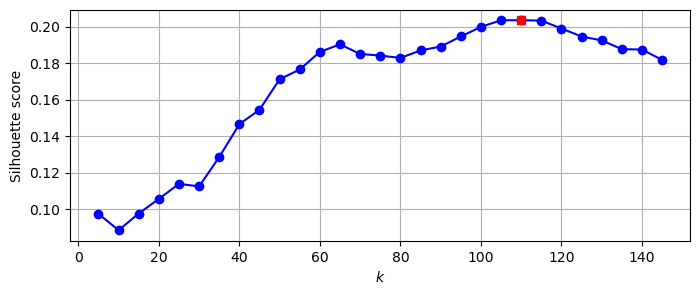

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score

#all the silhouette_score values for each model is stored in the list silhouette_scores
silhouette_scores = [silhouette_score(X_train, model.labels_) #the first input in the silhouette_score() function represents the trained dataset which contains the coordinations for the dataPoints, and the second input in the silhouette_score() function represents the labels which specifies which cluster does each data belong to.
                     for model in kmeans_per_k]
best_index = np.argmax(silhouette_scores) #using the function argmax() returns the index with the highest silhouette_score (Remember it returns the index), and if you look which k does this index corresponds to, you'll find that index 21 corresponds to k=110
best_k = k_range[best_index]
best_score = silhouette_scores[best_index]

plt.figure(figsize=(8, 3))
plt.plot(k_range, silhouette_scores, "bo-")
plt.xlabel("$k$") #the dollar signs is just for formatting.
plt.ylabel("Silhouette score")
plt.plot(best_k, best_score, "rs") #selecting a specific point since best_k = 110, and best_score=21, and then selecting a different color and shape for that coordination. we selected red and square.
plt.grid() #just shows the horizontal and vertical lines in the background
plt.show()

In [ ]:
#Printing all the silhouette_scores, one by one for each model.
for s in silhouette_scores:
    print(f"s={s}")
#below you will find the variable best_score, which gives the value of the best score out of these.

s=0.09742064028978348
s=0.08840612322092056
s=0.09755981713533401
s=0.10556609183549881
s=0.11379509419202805
s=0.112411729991436
s=0.1284928321838379
s=0.14649978280067444
s=0.15438704192638397
s=0.17110639810562134
s=0.1764565259218216
s=0.18609292805194855
s=0.19022028148174286
s=0.18493814766407013
s=0.1840784102678299
s=0.18278947472572327
s=0.1868715137243271
s=0.18902939558029175
s=0.1945282369852066
s=0.19977013766765594
s=0.20343050360679626
s=0.203441321849823
s=0.20324210822582245
s=0.1988924890756607
s=0.19451983273029327
s=0.1923786848783493
s=0.18760080635547638
s=0.1873672902584076
s=0.18171249330043793


In [ ]:
best_index #returning the index with the highest silhouette_score. Returing the INDEX, and if you look which k does this index corresponds to, you'll find that it corresponds to k=110

21

In [ ]:
best_k

110

In [29]:
best_score

0.203441321849823

It looks like the best number of clusters is quite high, at 120. You might have expected it to be 40, since there are 40 different people on the pictures. However, the same person may look quite different on different pictures (e.g., with or without glasses, or simply shifted left or right).

In [ ]:
#Printing all the inertias, one by one for each model.
for ik in kmeans_per_k:
    print(f"kk={ik.inertia_}")

kk=15223.3798828125
kk=13312.845703125
kk=11991.173828125
kk=11019.1083984375
kk=10303.359375
kk=9679.291015625
kk=8766.982421875
kk=8201.44921875
kk=7626.0947265625
kk=7017.05615234375
kk=6475.736328125
kk=6106.27001953125
kk=5773.798828125
kk=5477.421875
kk=5202.49609375
kk=4977.12353515625
kk=4660.42041015625
kk=4390.02294921875
kk=4107.72607421875
kk=3819.41650390625
kk=3594.40185546875
kk=3392.53466796875
kk=3194.470458984375
kk=3028.73291015625
kk=2847.22802734375
kk=2677.881103515625
kk=2526.5048828125
kk=2380.80712890625
kk=2229.96484375


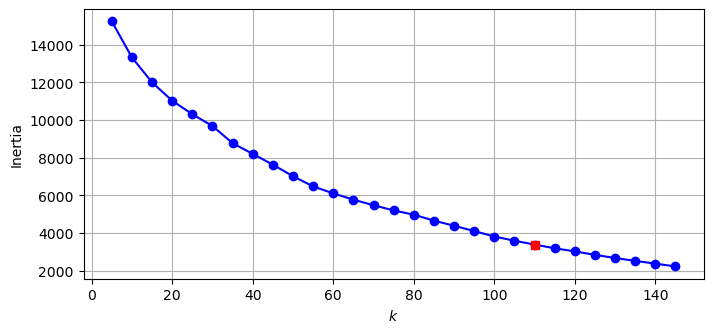

In [35]:
inertias = [model.inertia_ for model in kmeans_per_k] #all the interia values for each model is stored in the list inertias
best_inertia = inertias[best_index] #using the best_index that we previously calculated, and it was 21. Now we are getting the interia when k=110. 

plt.figure(figsize=(8, 3.5))
plt.plot(k_range, inertias, "bo-")
plt.xlabel("$k$")
plt.ylabel("Inertia")
plt.plot(best_k, best_inertia, "rs")
plt.grid()
plt.show()

The optimal number of clusters is not clear on this inertia diagram, as there is no obvious elbow, so let's stick with k=120.

In [38]:
kmeans_per_k[best_index]

,n_clusters,110
,init,'k-means++'
,n_init,'auto'
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


In [ ]:
best_model = kmeans_per_k[best_index] #since through the silhouette_score() function we have calculated that the best coordinations would be when number of cluster are 110, so now we are assigned that values of best index = 21, and best k = 110, and best interia = 3392.53466796875, all of these parameters I am assigning them to the value of the variable best_model

Number of cluster 110, that means that the best models will have 110 different clusters

*Exercise: Visualize the clusters: do you see similar faces in each cluster?*

Cluster 0


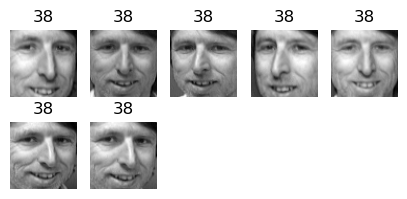

Cluster 1


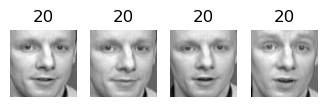

Cluster 2


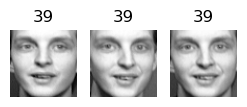

Cluster 3


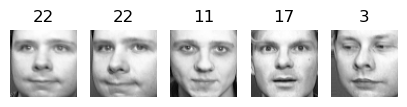

Cluster 4


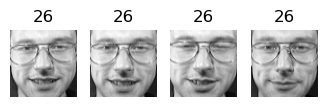

Cluster 5


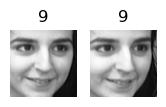

Cluster 6


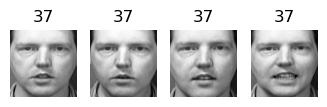

Cluster 7


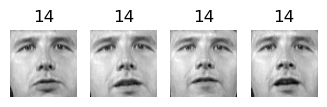

Cluster 8


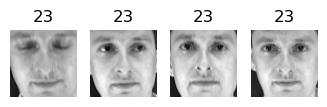

Cluster 9


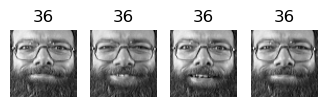

Cluster 10


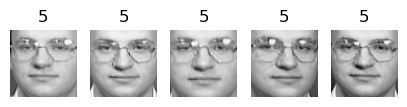

Cluster 11


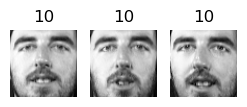

Cluster 12


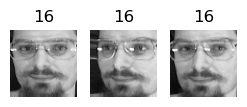

Cluster 13


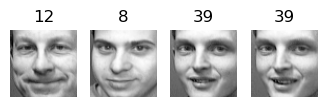

Cluster 14


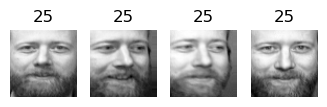

Cluster 15


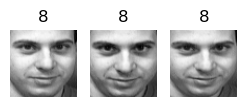

Cluster 16


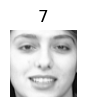

Cluster 17


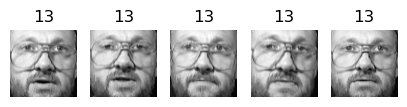

Cluster 18


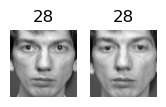

Cluster 19


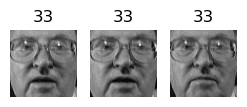

Cluster 20


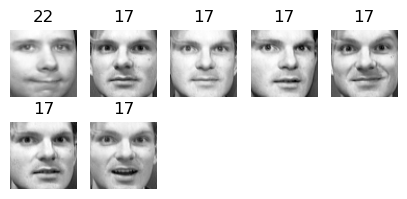

Cluster 21


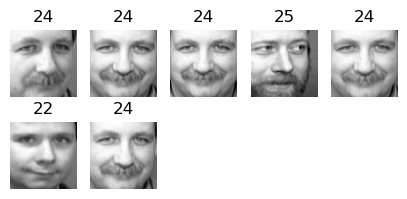

Cluster 22


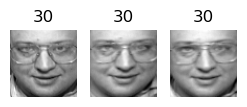

Cluster 23


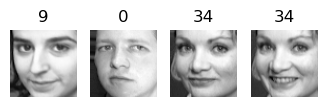

Cluster 24


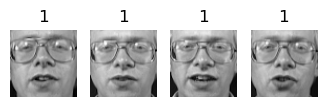

Cluster 25


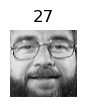

Cluster 26


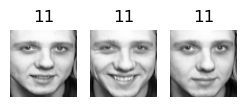

Cluster 27


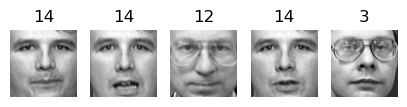

Cluster 28


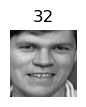

Cluster 29


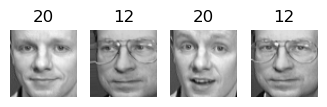

Cluster 30


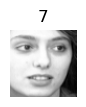

Cluster 31


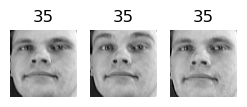

Cluster 32


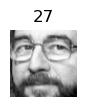

Cluster 33


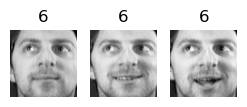

Cluster 34


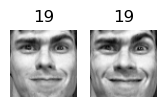

Cluster 35


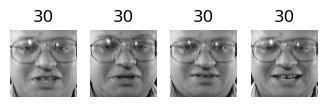

Cluster 36


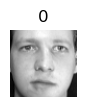

Cluster 37


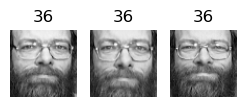

Cluster 38


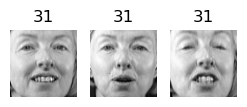

Cluster 39


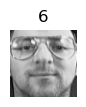

Cluster 40


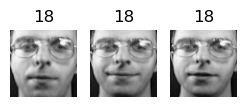

Cluster 41


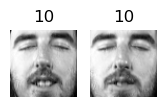

Cluster 42


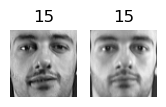

Cluster 43


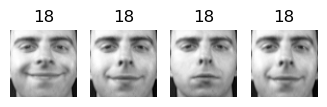

Cluster 44


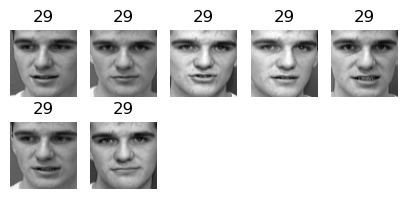

Cluster 45


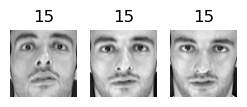

Cluster 46


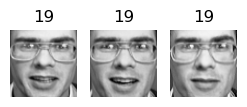

Cluster 47


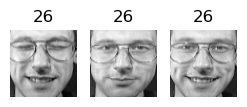

Cluster 48


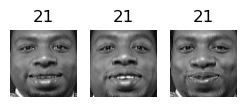

Cluster 49


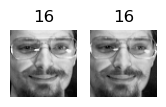

Cluster 50


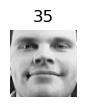

Cluster 51


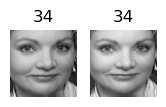

Cluster 52


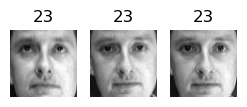

Cluster 53


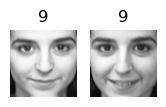

Cluster 54


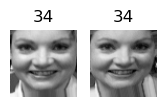

Cluster 55


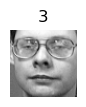

Cluster 56


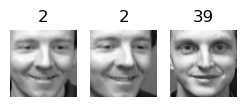

Cluster 57


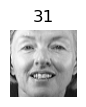

Cluster 58


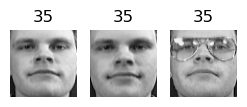

Cluster 59


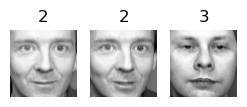

Cluster 60


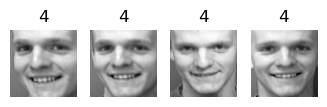

Cluster 61


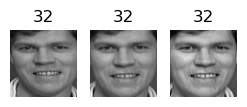

Cluster 62


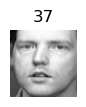

Cluster 63


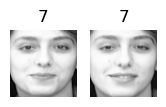

Cluster 64


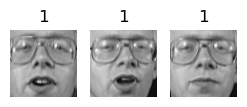

Cluster 65


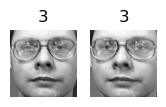

Cluster 66


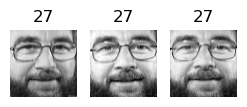

Cluster 67


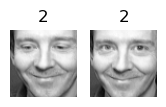

Cluster 68


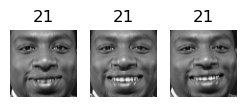

Cluster 69


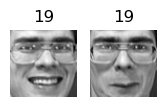

Cluster 70


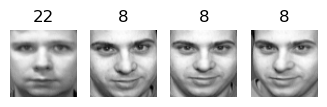

Cluster 71


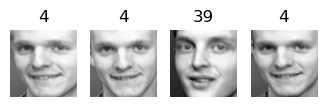

Cluster 72


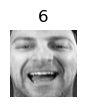

Cluster 73


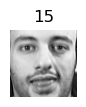

Cluster 74


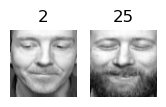

Cluster 75


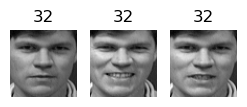

Cluster 76


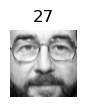

Cluster 77


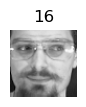

Cluster 78


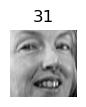

Cluster 79


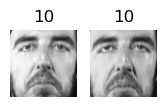

Cluster 80


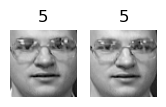

Cluster 81


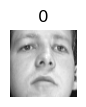

Cluster 82


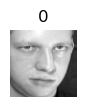

Cluster 83


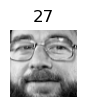

Cluster 84


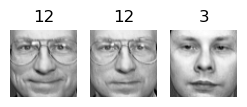

Cluster 85


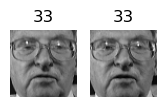

Cluster 86


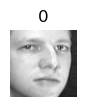

Cluster 87


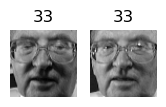

Cluster 88


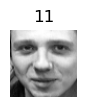

Cluster 89


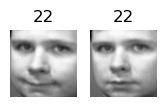

Cluster 90


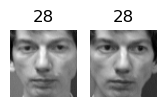

Cluster 91


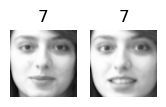

Cluster 92


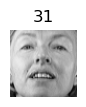

Cluster 93


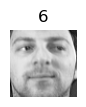

Cluster 94


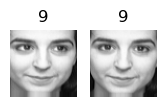

Cluster 95


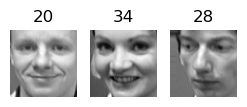

Cluster 96


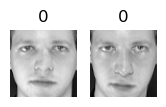

Cluster 97


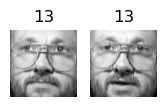

Cluster 98


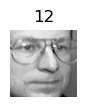

Cluster 99


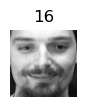

Cluster 100


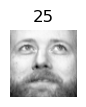

Cluster 101


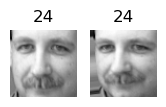

Cluster 102


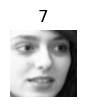

Cluster 103


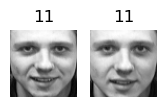

Cluster 104


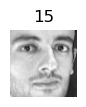

Cluster 105


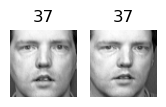

Cluster 106


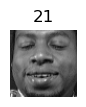

Cluster 107


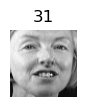

Cluster 108


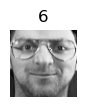

Cluster 109


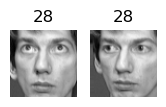

In [41]:
def plot_faces(faces, labels, n_cols=5): #labels here are going to be a value from 0-39, depending on which person is this from the 40 persons. 
    faces = faces.reshape(-1, 64, 64) #faces represents the images we see, and here we are choosing that they maybe 64 pixels by 64 pixels
    n_rows = (len(faces) - 1) // n_cols + 1
    plt.figure(figsize=(n_cols, n_rows * 1.1))
    for index, (face, label) in enumerate(zip(faces, labels)):
        plt.subplot(n_rows, n_cols, index + 1)
        plt.imshow(face, cmap="gray")
        plt.axis("off")
        plt.title(label)
    plt.show()

for cluster_id in np.unique(best_model.labels_):
    print("Cluster", cluster_id)
    in_cluster = best_model.labels_==cluster_id
    faces = X_train[in_cluster]
    labels = y_train[in_cluster]
    plot_faces(faces, labels)

About 2 out of 3 clusters are useful: that is, they contain at least 2 pictures, all of the same person. However, the rest of the clusters have either one or more intruders, or they have just a single picture.

Clustering images this way may be too imprecise to be directly useful when training a model (as we will see below), but it can be tremendously useful when labeling images in a new dataset: it will usually make labelling much faster.

In [ ]:
best_inertia #that's interia when k=110, which means that the number of cluusters are 110. So when the number of clusters are 110, we have an interia of 3392.53466796875

3392.53466796875

## Answer for the exercise 

In [ ]:
import numpy as np
cluster_counts = {} #initializing an empty dictionary 
for index, person in enumerate(best_model.labels_): #looping through each image, and assigning the image index to the variable index, and assigning the label(clusterID) to the variable person
    if person not in cluster_counts: #checking if the label(ClusterID) is in the dictionary cluster_counts
            cluster_counts[person] = [] #and if the label(PersonID) is not in the dictionary cluster_counts; then in the dictionary, I will create a new key(in this case creating a new ClusterID), and I will assign it to an empty list, and the empty list is the value(which stores the image indices that belong to this cluster) for my key(which stores which cluster out of 110 this is)
    cluster_counts[person].append(index) #depending on which cluster does the image belong to, the image index is going to be added to that cluster. We have 40 distinct persons and are using 400 images, and according the sillhoutte score the best number of clusters to be used is 110 clusters.

In [ ]:
len(cluster_counts) #just to confirm the I am working with index 21, and 110 clusters, and an interia of 3392.53466796875

110

In [66]:
clustersWith_1_image = {cluster_id: indices for cluster_id, indices in cluster_counts.items() if len(indices) == 1}
for cluster_id, indices in clustersWith_1_image.items():
      cluster_labels = y_train[indices]

In [95]:
print("There are " + str(len(clustersWith_1_image)) + " clusters that have only one image")
print("clusters that has only 1 image:", clustersWith_1_image)
for cid, inds in clustersWith_1_image.items(): #clusterID is the key, and the index is the value
    print("Cluster", cid, "has indices:", inds, "-> ylabels:", y_train[inds]) #cid stands for cluster ID, and inds stands for the index number, and finally ylabels is used to identify the each person from another person since we have 40 person in this dataset


There are 31 clusters that have only one image
clusters that has only 1 image: {28: [28], 98: [31], 62: [34], 77: [37], 99: [40], 30: [41], 107: [63], 78: [69], 76: [119], 100: [124], 81: [128], 92: [135], 16: [139], 50: [146], 32: [147], 83: [163], 25: [165], 55: [170], 36: [200], 57: [202], 104: [207], 108: [215], 102: [218], 72: [219], 39: [223], 73: [234], 88: [235], 86: [246], 93: [249], 106: [254], 82: [263]}
Cluster 28 has indices: [28] -> ylabels: [32]
Cluster 98 has indices: [31] -> ylabels: [12]
Cluster 62 has indices: [34] -> ylabels: [37]
Cluster 77 has indices: [37] -> ylabels: [16]
Cluster 99 has indices: [40] -> ylabels: [16]
Cluster 30 has indices: [41] -> ylabels: [7]
Cluster 107 has indices: [63] -> ylabels: [31]
Cluster 78 has indices: [69] -> ylabels: [31]
Cluster 76 has indices: [119] -> ylabels: [27]
Cluster 100 has indices: [124] -> ylabels: [25]
Cluster 81 has indices: [128] -> ylabels: [0]
Cluster 92 has indices: [135] -> ylabels: [31]
Cluster 16 has indices: [

### So I will continue by analying the clusters with 2 images 

##### I will print the cluster number and the labels(personIDs) of that cluster, and lastly I will also attach the index of the image from the traning model

In [ ]:
clustersWith_2_images = {cluster_id: indices for cluster_id, indices in cluster_counts.items() if len(indices) == 2}
for cluster_id, indices in clustersWith_2_images.items():
      cluster_labels = y_train[indices]

In [ ]:
counterFor_same_2images = 0
print("All clusters that has 2 images:", clustersWith_2_images)
for cid, inds in clustersWith_2_images.items(): #clusterID is the key, and the index is the value
    print("Cluster", cid, "has indices:", inds, "-> ylabels:", y_train[inds]) #cid stands for cluster ID, and inds stands for the index number, and finally ylabels is used to identify the each person from another person since we have 40 person in this dataset


All clusters that has 3 images: {101: [9, 30], 5: [13, 251], 49: [15, 159], 103: [20, 205], 42: [21, 237], 63: [39, 233], 74: [43, 230], 34: [51, 96], 53: [59, 70], 65: [61, 83], 91: [64, 101], 54: [73, 81], 105: [99, 120], 69: [100, 267], 96: [105, 161], 41: [117, 266], 109: [131, 255], 94: [143, 192], 67: [145, 209], 51: [148, 184], 80: [150, 236], 87: [162, 187], 89: [169, 225], 85: [173, 204], 90: [174, 239], 18: [212, 277], 97: [252, 275], 79: [271, 272]}
Cluster 101 has indices: [9, 30] -> ylabels: [24 24]
Cluster 5 has indices: [13, 251] -> ylabels: [9 9]
Cluster 49 has indices: [15, 159] -> ylabels: [16 16]
Cluster 103 has indices: [20, 205] -> ylabels: [11 11]
Cluster 42 has indices: [21, 237] -> ylabels: [15 15]
Cluster 63 has indices: [39, 233] -> ylabels: [7 7]
Cluster 74 has indices: [43, 230] -> ylabels: [ 2 25]
Cluster 34 has indices: [51, 96] -> ylabels: [19 19]
Cluster 53 has indices: [59, 70] -> ylabels: [9 9]
Cluster 65 has indices: [61, 83] -> ylabels: [3 3]
Cluster

In [92]:
print("clusters with 2 images that have more than on one personID in the same cluster, and that are not good:")
for cid, inds in clustersWith_2_images.items():
    labels_in_cluster = y_train[inds] #assigning the the labels, which represents IDs for the people, and in this case we are refering to those who have images in clusters that have 2 images, so we are getting those labels(person IDs), and storing it in the varaiable labels_in_cluster
    samePerson = set(labels_in_cluster) #using the the function set() to get the number of distinct images (of course distinct, so excluding duplicates)

    if len(samePerson) != 1: #checking if the images have the same label that refers to the same person of out the 40 people, excluding duplicated images 
        print(f"Cluster {cid} has mixed labels: {samePerson}")

clusters with 2 images that have more than on one personID in the same cluster, and that are not good:
Cluster 74 has mixed labels: {25, 2}


In [93]:
counterFor_same_2images = 0
print("clusters of same person with 2 images:")
for cid, inds in clustersWith_2_images.items():
    labels_in_cluster = y_train[inds] #assigning the the labels, which represents IDs for the people, and in this case we are refering to those who have images in clusters that have 2 images, so we are getting those labels(person IDs), and storing it in the varaiable labels_in_cluster
    samePerson = set(labels_in_cluster) #using the the function set() to get the number of distinct images (of course distinct, so excluding duplicates)

    if len(samePerson) == 1: #checking if the images have the same label that refers to the same person of out the 40 people, excluding duplicated images 
        print(f"Cluster {cid} has the same label: {list(samePerson)[0]}") #using the list function for shorter code and best practice rather than having to do a loop.
        counterFor_same_2images += 1
print(f"total clusters for same person with 3 images is {counterFor_same_2images}")

clusters of same person with 2 images:
Cluster 101 has the same label: 24
Cluster 5 has the same label: 9
Cluster 49 has the same label: 16
Cluster 103 has the same label: 11
Cluster 42 has the same label: 15
Cluster 63 has the same label: 7
Cluster 34 has the same label: 19
Cluster 53 has the same label: 9
Cluster 65 has the same label: 3
Cluster 91 has the same label: 7
Cluster 54 has the same label: 34
Cluster 105 has the same label: 37
Cluster 69 has the same label: 19
Cluster 96 has the same label: 0
Cluster 41 has the same label: 10
Cluster 109 has the same label: 28
Cluster 94 has the same label: 9
Cluster 67 has the same label: 2
Cluster 51 has the same label: 34
Cluster 80 has the same label: 5
Cluster 87 has the same label: 33
Cluster 89 has the same label: 22
Cluster 85 has the same label: 33
Cluster 90 has the same label: 28
Cluster 18 has the same label: 28
Cluster 97 has the same label: 13
Cluster 79 has the same label: 10
total clusters for same person with 3 images is 2

### So I will continue by analying the clusters with 3 images 

##### I will print the cluster number and the labels(personIDs) of that cluster, and lastly I will also attach the index of the image from the traning model

In [88]:
clustersWith_3_images = {cluster_id: indices for cluster_id, indices in cluster_counts.items() if len(indices) == 3}
for cluster_id, indices in clustersWith_3_images.items():
      cluster_labels = y_train[indices]

In [89]:
print("All clusters that has 3 images:", clustersWith_3_images) #printing all the clusters that has 3 images 
for cid, inds in clustersWith_3_images.items(): #clusterID is the key, and the index is the value
    print("Cluster", cid, "-> ylabels:", y_train[inds], "has indices:", inds) #cid stands for cluster ID, and inds stands for the index number, and finally ylabels is used to identify the each person from another person since we have 40 person in this dataset


All clusters that has 3 images: {33: [3, 97, 111], 56: [5, 125, 268], 22: [6, 36, 141], 12: [11, 74, 217], 40: [17, 56, 231], 15: [24, 133, 195], 19: [25, 176, 274], 48: [32, 68, 116], 46: [35, 118, 242], 84: [49, 151, 185], 26: [52, 94, 273], 59: [53, 142, 154], 75: [58, 210, 229], 66: [60, 129, 262], 61: [71, 181, 214], 52: [72, 79, 112], 31: [75, 103, 156], 38: [77, 95, 228], 11: [80, 206, 238], 37: [82, 179, 196], 45: [87, 127, 190], 64: [88, 93, 177], 95: [92, 107, 167], 68: [106, 114, 153], 58: [126, 194, 260], 47: [157, 186, 248], 2: [198, 243, 270]}
Cluster 33 -> ylabels: [6 6 6] has indices: [3, 97, 111]
Cluster 56 -> ylabels: [ 2  2 39] has indices: [5, 125, 268]
Cluster 22 -> ylabels: [30 30 30] has indices: [6, 36, 141]
Cluster 12 -> ylabels: [16 16 16] has indices: [11, 74, 217]
Cluster 40 -> ylabels: [18 18 18] has indices: [17, 56, 231]
Cluster 15 -> ylabels: [8 8 8] has indices: [24, 133, 195]
Cluster 19 -> ylabels: [33 33 33] has indices: [25, 176, 274]
Cluster 48 -> y

In [90]:
print("clusters with 3 images that have more than on one personID in the same cluster, and that are not good:")
for cid, inds in clustersWith_3_images.items():
    labels_in_cluster = y_train[inds] #assigning the the labels, which represents IDs for the people, and in this case we are refering to those who have images in clusters that have 3 images, so we are getting those labels(person IDs), and storing it in the varaiable labels_in_cluster
    samePerson = set(labels_in_cluster) #using the the function set() to get the number of distinct images (of course distinct, so excluding duplicates)

    if len(samePerson) != 1: #checking if the images have the same label that refers to the same person of out the 40 people, excluding duplicated images 
        print(f"Cluster {cid} has mixed labels: {samePerson}")


clusters with 3 images that have more than on one personID in the same cluster, and that are not good:
Cluster 56 has mixed labels: {2, 39}
Cluster 84 has mixed labels: {3, 12}
Cluster 59 has mixed labels: {2, 3}
Cluster 95 has mixed labels: {34, 20, 28}


In [91]:
counterFor_same_3images = 0
print("clusters of same person with 3 images:")
for cid, inds in clustersWith_3_images.items():
    labels_in_cluster = y_train[inds] #assigning the the labels, which represents IDs for the people, and in this case we are refering to those who have images in clusters that have 3 images, so we are getting those labels(person IDs), and storing it in the varaiable labels_in_cluster
    samePerson = set(labels_in_cluster) #using the the function set() to get the number of distinct images (of course distinct, so excluding duplicates)

    if len(samePerson) == 1: #checking if the images have the same label that refers to the same person of out the 40 people, excluding duplicated images 
        print(f"Cluster {cid} has the same label: {list(samePerson)[0]}") #using the list function for shorter code and best practice rather than having to do a loop.
        counterFor_same_3images += 1
print(f"total clusters for same person with 3 images is {counterFor_same_3images}")

clusters of same person with 3 images:
Cluster 33 has the same label: 6
Cluster 22 has the same label: 30
Cluster 12 has the same label: 16
Cluster 40 has the same label: 18
Cluster 15 has the same label: 8
Cluster 19 has the same label: 33
Cluster 48 has the same label: 21
Cluster 46 has the same label: 19
Cluster 26 has the same label: 11
Cluster 75 has the same label: 32
Cluster 66 has the same label: 27
Cluster 61 has the same label: 32
Cluster 52 has the same label: 23
Cluster 31 has the same label: 35
Cluster 38 has the same label: 31
Cluster 11 has the same label: 10
Cluster 37 has the same label: 36
Cluster 45 has the same label: 15
Cluster 64 has the same label: 1
Cluster 68 has the same label: 21
Cluster 58 has the same label: 35
Cluster 47 has the same label: 26
Cluster 2 has the same label: 39
total clusters for same person with 3 images is 23


### So I will continue by analying the clusters with 4 images 

In [99]:
clustersWith_4_images = {cluster_id: indices for cluster_id, indices in cluster_counts.items() if len(indices) == 4}
for cluster_id, indices in clustersWith_4_images.items():
      cluster_labels = y_train[indices]

In [ ]:
print("clusters with 4 images that have more than on one personID in the same cluster, and that are not good:")
for cid, inds in clustersWith_4_images.items():
    labels_in_cluster = y_train[inds] #assigning the the labels, which represents IDs for the people, and in this case we are refering to those who have images in clusters that have 4 images, so we are getting those labels(person IDs), and storing it in the varaiable labels_in_cluster
    samePerson = set(labels_in_cluster) #using the the function set() to get the number of distinct images (of course distinct, so excluding duplicates)

    if len(samePerson) != 1: #checking if the images have the same label that refers to the same person of out the 40 people, excluding duplicated images 
        print(f"Cluster {cid} has mixed labels: {samePerson}")


clusters with 4 images that have more than on one personID in the same cluster, and that are not good:
Cluster 29 has mixed labels: {20, 12}
Cluster 13 has mixed labels: {8, 12, 39}
Cluster 70 has mixed labels: {8, 22}
Cluster 23 has mixed labels: {0, 9, 34}
Cluster 71 has mixed labels: {4, 39}


In [102]:
counterFor_same_4images = 0
print("clusters of same person with 4 images:")
for cid, inds in clustersWith_4_images.items():
    labels_in_cluster = y_train[inds] #assigning the the labels, which represents IDs for the people, and in this case we are refering to those who have images in clusters that have 4 images, so we are getting those labels(person IDs), and storing it in the varaiable labels_in_cluster
    samePerson = set(labels_in_cluster) #using the the function set() to get the number of distinct images (of course distinct, so excluding duplicates)

    if len(samePerson) == 1: #checking if the images have the same label that refers to the same person of out the 40 people, excluding duplicated images 
        print(f"Cluster {cid} has the same label: {list(samePerson)[0]}") #using the list function for shorter code and best practice rather than having to do a loop.
        counterFor_same_4images += 1
print(f"total clusters for same person with 4 images is {counterFor_same_4images}")

clusters of same person with 4 images:
Cluster 35 has the same label: 30
Cluster 43 has the same label: 18
Cluster 1 has the same label: 20
Cluster 4 has the same label: 26
Cluster 7 has the same label: 14
Cluster 9 has the same label: 36
Cluster 8 has the same label: 23
Cluster 6 has the same label: 37
Cluster 14 has the same label: 25
Cluster 24 has the same label: 1
Cluster 60 has the same label: 4
total clusters for same person with 4 images is 11


### So I will continue by analying the clusters with 5 images 

In [103]:
clustersWith_5_images = {cluster_id: indices for cluster_id, indices in cluster_counts.items() if len(indices) == 5}
for cluster_id, indices in clustersWith_5_images.items():
      cluster_labels = y_train[indices]

In [104]:
print("clusters with 5 images that have more than on one personID in the same cluster, and that are not good:")
for cid, inds in clustersWith_5_images.items():
    labels_in_cluster = y_train[inds] #assigning the the labels, which represents IDs for the people, and in this case we are refering to those who have images in clusters that have 5 images, so we are getting those labels(person IDs), and storing it in the varaiable labels_in_cluster
    samePerson = set(labels_in_cluster) #using the the function set() to get the number of distinct images (of course distinct, so excluding duplicates)

    if len(samePerson) != 1: #checking if the images have the same label that refers to the same person of out the 40 people, excluding duplicated images 
        print(f"Cluster {cid} has mixed labels: {samePerson}")


clusters with 5 images that have more than on one personID in the same cluster, and that are not good:
Cluster 27 has mixed labels: {3, 12, 14}
Cluster 3 has mixed labels: {3, 17, 11, 22}


In [106]:

print("clusters of same person with 5 images:")
for cid, inds in clustersWith_5_images.items():
    labels_in_cluster = y_train[inds] #assigning the the labels, which represents IDs for the people, and in this case we are refering to those who have images in clusters that have 5 images, so we are getting those labels(person IDs), and storing it in the varaiable labels_in_cluster
    samePerson = set(labels_in_cluster) #using the the function set() to get the number of distinct images (of course distinct, so excluding duplicates)

    if len(samePerson) == 1: #checking if the images have the same label that refers to the same person of out the 40 people, excluding duplicated images 
        print(f"Cluster {cid} has the same label: {list(samePerson)[0]}") #using the list function for shorter code and best practice rather than having to do a loop.

clusters of same person with 5 images:
Cluster 10 has the same label: 5
Cluster 17 has the same label: 13


### So I will continue by analying the clusters with 6 images 

In [107]:
clustersWith_6_images = {cluster_id: indices for cluster_id, indices in cluster_counts.items() if len(indices) == 6}
for cluster_id, indices in clustersWith_6_images.items():
      cluster_labels = y_train[indices]

In [121]:
len(clustersWith_6_images.items())

0

### So I will continue by finally analying the clusters with 7 images 

In [122]:
clustersWith_7_images = {cluster_id: indices for cluster_id, indices in cluster_counts.items() if len(indices) == 7}
for cluster_id, indices in clustersWith_7_images.items():
      cluster_labels = y_train[indices]

In [123]:
print("clusters with 7 images that have more than on one personID in the same cluster, and that are not good:")
for cid, inds in clustersWith_7_images.items():
    labels_in_cluster = y_train[inds] #assigning the the labels, which represents IDs for the people, and in this case we are refering to those who have images in clusters that have 7 images, so we are getting those labels(person IDs), and storing it in the varaiable labels_in_cluster
    samePerson = set(labels_in_cluster) #using the the function set() to get the number of distinct images (of course distinct, so excluding duplicates)

    if len(samePerson) != 1: #checking if the images have the same label that refers to the same person of out the 40 people, excluding duplicated images 
        print(f"Cluster {cid} has mixed labels: {samePerson}")

clusters with 7 images that have more than on one personID in the same cluster, and that are not good:
Cluster 21 has mixed labels: {24, 25, 22}
Cluster 20 has mixed labels: {17, 22}


In [126]:
print("clusters of same person with 7 images:")
for cid, inds in clustersWith_7_images.items():
    labels_in_cluster = y_train[inds] #assigning the the labels, which represents IDs for the people, and in this case we are refering to those who have images in clusters that have 7 images, so we are getting those labels(person IDs), and storing it in the varaiable labels_in_cluster
    samePerson = set(labels_in_cluster) #using the the function set() to get the number of distinct images (of course distinct, so excluding duplicates)

    if len(samePerson) == 1: #checking if the images have the same label that refers to the same person of out the 40 people, excluding duplicated images 
        print(f"Cluster {cid} has the same label: {list(samePerson)[0]}") #using the list function for shorter code and best practice rather than having to do a loop.
        counterFor_same_7images += 1

clusters of same person with 7 images:
Cluster 0 has the same label: 38
Cluster 44 has the same label: 29


 2 + 2 + 11 + 23 + 27 = 65 

In total, 65 clusters have been able to capture images of unique person

## Conclusion 

Looking at the results I can see that there are couple of clusters overcrowded with 7 images(like cluster44, cluster21, cluster20, cluster0); even though, cluster44 and cluster0 have 7 images of the same person in each, and they are considered one of our best current data because of their large size and consistency in collecting 7 images out of 10 images of a distinct person in one cluster, so they provide valiable data for model training.


There are also some clusters that have intruders like(cluster84, cluster71, cluster70), which would require data cleaning. 


And there are other clusters that have no relation to each other from the perspective of having a distinct person, and it is just a cluster formed of images of different person, one image for each person(like Cluster95, cluster74), which would also require data cleaning.


And there are many cluster, 31 clusters, who have only one image. These 31 clusters may be of no use when it comes to model training because they provide little to no useful information, but could be used to help identify outliers.

But there are also some good clusters which have 2 images of the same person(like cluster109, cluster105, cluster103, cluster101, cluster97, cluster96, cluster94, cluster91, cluster90, cluster89, cluster87, cluster80, cluster79, cluster69, cluster67, cluster65), which could be used for model training.

But there are also some really great clusters which have 3 images of the same person(like cluster75, cluster68, cluster66, cluster64), which also could be used for model training.

And there are two clusters who have only 4 images of the same person with no intruders in both clusters, but the 4 images are divided between 2 clusters. (Like cluster87, cluster85)

In conclusion, Out of the total 110 clusters, we have 65 clusters have been able to capture images of a unique person, having at least two images of the same person. So more than 59% of the clusters have captured at least two images of the same person.